# Exploratory Data Analysis of E-commerce Sales and Customer Behaviour

**Business:** Maven Fuzzy Factory  
**Environment:** Databricks  
**Tools:** PySpark, Pandas, NumPy and Matplotlib

### Objective
Explore customer behaviour, sales patterns and business performance using exploratory data analysis and statistical techniques. This notebook follows the four tasks in the AnalystLab brief: data exploration, EDA, statistical analysis/visualisation, and interpretation/recommendations.



## Databricks setup


In [0]:

# Load the six datasets from the Databricks catalog.
# IMPORTANT: Backticks are required around e-commerce
# because the schema name contains a hyphen.

sessions = spark.read.table(
    "`workspace`.`e-commerce`.`website_sessions`"
)

pageviews = spark.read.table(
    "`workspace`.`e-commerce`.`website_pageviews`"
)

orders = spark.read.table(
    "`workspace`.`e-commerce`.`orders_mav`"
)

order_items = spark.read.table(
    "`workspace`.`e-commerce`.`order_items`"
)

refunds = spark.read.table(
    "`workspace`.`e-commerce`.`order_item_refunds`"
)

products = spark.read.table(
    "`workspace`.`e-commerce`.`products`"
)

# Confirm that all six Spark DataFrames have been created.
print("All six datasets loaded successfully!")

# Display the dataset names.
print("Datasets available:")
print([
    "website_sessions",
    "website_pageviews",
    "orders_mav",
    "order_items",
    "order_item_refunds",
    "products"
])


All six datasets loaded successfully!
Datasets available:
['website_sessions', 'website_pageviews', 'orders_mav', 'order_items', 'order_item_refunds', 'products']


## Task 1 – Data exploration and preparation
### 1.1 Examine structure, columns, types and sample records


In [0]:

# Store the six datasets in a dictionary.
# This allows us to inspect them consistently.

datasets = {
    "website_sessions": sessions,
    "website_pageviews": pageviews,
    "orders_mav": orders,
    "order_items": order_items,
    "order_item_refunds": refunds,
    "products": products
}

# Inspect the structure of each Spark DataFrame.
for name, df in datasets.items():

    # Display the dataset name.
    print(f"\n===== {name} =====")

    # Count the total number of rows.
    print("Number of rows:", df.count())

    # Count the total number of columns.
    print("Number of columns:", len(df.columns))

    # Display all column names.
    print("\nColumn names:")
    print(df.columns)

    # Display the column data types.
    print("\nData types:")
    print(df.dtypes)

    # Display the first five records.
    print("\nFirst five records:")
    display(df.limit(5))



===== website_sessions =====
Number of rows: 472871
Number of columns: 9

Column names:
['website_session_id', 'created_at', 'user_id', 'is_repeat_session', 'utm_source', 'utm_campaign', 'utm_content', 'device_type', 'http_referer']

Data types:
[('website_session_id', 'bigint'), ('created_at', 'string'), ('user_id', 'bigint'), ('is_repeat_session', 'bigint'), ('utm_source', 'string'), ('utm_campaign', 'string'), ('utm_content', 'string'), ('device_type', 'string'), ('http_referer', 'string')]

First five records:


website_session_id,created_at,user_id,is_repeat_session,utm_source,utm_campaign,utm_content,device_type,http_referer
1,3/19/2012 8:04,1,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
2,3/19/2012 8:16,2,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
3,3/19/2012 8:26,3,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
4,3/19/2012 8:37,4,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
5,3/19/2012 9:00,5,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com



===== website_pageviews =====
Number of rows: 1048575
Number of columns: 4

Column names:
['website_pageview_id', 'created_at', 'website_session_id', 'pageview_url']

Data types:
[('website_pageview_id', 'bigint'), ('created_at', 'string'), ('website_session_id', 'bigint'), ('pageview_url', 'string')]

First five records:


website_pageview_id,created_at,website_session_id,pageview_url
1,3/19/2012 8:04,1,/home
2,3/19/2012 8:16,2,/home
3,3/19/2012 8:26,3,/home
4,3/19/2012 8:37,4,/home
5,3/19/2012 9:00,5,/home



===== orders_mav =====
Number of rows: 32313
Number of columns: 8

Column names:
['order_id', 'created_at', 'website_session_id', 'user_id', 'primary_product_id', 'items_purchased', 'price_usd', 'cogs_usd']

Data types:
[('order_id', 'bigint'), ('created_at', 'string'), ('website_session_id', 'bigint'), ('user_id', 'bigint'), ('primary_product_id', 'bigint'), ('items_purchased', 'bigint'), ('price_usd', 'double'), ('cogs_usd', 'double')]

First five records:


order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
1,3/19/2012 10:42,20,20,1,1,49.99,19.49
2,3/19/2012 19:27,104,104,1,1,49.99,19.49
3,3/20/2012 6:44,147,147,1,1,49.99,19.49
4,3/20/2012 9:41,160,160,1,1,49.99,19.49
5,3/20/2012 11:28,177,177,1,1,49.99,19.49


... (2 outputs left out)


===== order_item_refunds =====
Number of rows: 1731
Number of columns: 5

Column names:
['order_item_refund_id', 'created_at', 'order_item_id', 'order_id', 'refund_amount_usd']

Data types:
[('order_item_refund_id', 'bigint'), ('created_at', 'string'), ('order_item_id', 'bigint'), ('order_id', 'bigint'), ('refund_amount_usd', 'double')]

First five records:


order_item_refund_id,created_at,order_item_id,order_id,refund_amount_usd
1,4/6/2012 11:32,57,57,49.99
2,4/13/2012 1:09,74,74,49.99
3,4/15/2012 7:03,71,71,49.99
4,4/17/2012 20:00,118,118,49.99
5,4/22/2012 20:53,116,116,49.99



===== products =====
Number of rows: 4
Number of columns: 3

Column names:
['product_id', 'created_at', 'product_name']

Data types:
[('product_id', 'bigint'), ('created_at', 'string'), ('product_name', 'string')]

First five records:


product_id,created_at,product_name
1,3/19/2012 8:00,The Original Mr. Fuzzy
2,1/6/2013 13:00,The Forever Love Bear
3,12/12/2013 9:00,The Birthday Sugar Panda
4,2/5/2014 10:00,The Hudson River Mini bear


### 1.2 Identify missing values


In [0]:

# ==========================================================
# TASK 1.2: MISSING VALUES ANALYSIS
# ==========================================================

# Import Spark SQL functions.
from pyspark.sql import functions as F

# Store missing-value results for all datasets.
missing_results = []

# Loop through each dataset.
for name, df in datasets.items():

    print(f"\n===== {name} =====")

    # Calculate missing values for every column.
    expressions = []

    for column_name in df.columns:

        # Count NULL values.
        null_count = F.sum(
            F.when(F.col(column_name).isNull(), 1).otherwise(0)
        )

        expressions.append(
            null_count.alias(column_name)
        )

        # Also identify blank strings in text columns.
        if dict(df.dtypes)[column_name] == "string":

            blank_count = F.sum(
                F.when(
                    F.trim(F.col(column_name)) == "",
                    1
                ).otherwise(0)
            )

            expressions.append(
                blank_count.alias(column_name + "_blank")
            )

    # Execute the missing-value calculations.
    result = df.agg(*expressions).collect()[0]

    # Store the results.
    total_rows = df.count()

    for column_name in df.columns:

        null_count = result[column_name] or 0

        blank_count = 0

        if dict(df.dtypes)[column_name] == "string":
            blank_count = result[column_name + "_blank"] or 0

        missing_results.append({
            "dataset": name,
            "column": column_name,
            "null_values": null_count,
            "blank_values": blank_count,
            "total_rows": total_rows
        })

# Convert results into a Pandas DataFrame.
missing_df = pd.DataFrame(missing_results)

# Display the missing-value report.
display(missing_df)



===== website_sessions =====

===== website_pageviews =====

===== orders_mav =====

===== order_items =====

===== order_item_refunds =====

===== products =====


dataset,column,null_values,blank_values,total_rows
website_sessions,website_session_id,0,0,472871
website_sessions,created_at,0,0,472871
website_sessions,user_id,0,0,472871
website_sessions,is_repeat_session,0,0,472871
website_sessions,utm_source,0,0,472871
website_sessions,utm_campaign,0,0,472871
website_sessions,utm_content,0,0,472871
website_sessions,device_type,0,0,472871
website_sessions,http_referer,0,0,472871
website_pageviews,website_pageview_id,0,0,1048575


### 1.3 Check duplicate primary keys


In [0]:
# Define the primary key for each dataset.
# These columns should uniquely identify individual records.

primary_keys = {
    "website_sessions": "website_session_id",
    "website_pageviews": "website_pageview_id",
    "orders_mav": "order_id",
    "order_items": "order_item_id",
    "order_item_refunds": "order_item_refund_id",
    "products": "product_id"
}

# Create a list to store duplicate analysis results.
duplicate_results = []

# Examine each dataset.
for name, df in datasets.items():

    print(f"\n===== {name} =====")

    # Count all records in the dataset.
    total_rows = df.count()

    # Count distinct complete records.
    distinct_rows = df.dropDuplicates().count()

    # Calculate full-row duplicates.
    duplicate_rows = total_rows - distinct_rows

    # Identify the primary key.
    key_column = primary_keys[name]

    # Identify duplicated primary key values.
    duplicate_keys = (
        df.groupBy(key_column)
          .count()
          .filter(F.col("count") > 1)
    )

    # Count the number of duplicated key groups.
    duplicate_key_groups = duplicate_keys.count()

    # Count excess records associated with duplicate keys.
    duplicate_key_records = (
        duplicate_keys
        .select(
            F.sum(F.col("count") - 1).alias("duplicates")
        )
        .first()["duplicates"]
    )

    if duplicate_key_records is None:
        duplicate_key_records = 0

    # Display results.
    print("Total records:", total_rows)
    print("Distinct records:", distinct_rows)
    print("Full-row duplicates:", duplicate_rows)
    print("Duplicate primary key groups:", duplicate_key_groups)
    print("Excess primary key records:", duplicate_key_records)

    # Save results.
    duplicate_results.append({
        "dataset": name,
        "total_rows": total_rows,
        "distinct_rows": distinct_rows,
        "full_row_duplicates": duplicate_rows,
        "duplicate_key_groups": duplicate_key_groups,
        "excess_key_records": duplicate_key_records
    })

# Convert the results into a Pandas DataFrame.
duplicate_df = pd.DataFrame(duplicate_results)

# Display the final duplicate analysis report.
display(duplicate_df)



===== website_sessions =====
Total records: 472871
Distinct records: 472871
Full-row duplicates: 0
Duplicate primary key groups: 0
Excess primary key records: 0

===== website_pageviews =====
Total records: 1048575
Distinct records: 1048575
Full-row duplicates: 0
Duplicate primary key groups: 0
Excess primary key records: 0

===== orders_mav =====
Total records: 32313
Distinct records: 32313
Full-row duplicates: 0
Duplicate primary key groups: 0
Excess primary key records: 0

===== order_items =====
Total records: 40025
Distinct records: 40025
Full-row duplicates: 0
Duplicate primary key groups: 0
Excess primary key records: 0

===== order_item_refunds =====
Total records: 1731
Distinct records: 1731
Full-row duplicates: 0
Duplicate primary key groups: 0
Excess primary key records: 0

===== products =====
Total records: 4
Distinct records: 4
Full-row duplicates: 0
Duplicate primary key groups: 0
Excess primary key records: 0


dataset,total_rows,distinct_rows,full_row_duplicates,duplicate_key_groups,excess_key_records
website_sessions,472871,472871,0,0,0
website_pageviews,1048575,1048575,0,0,0
orders_mav,32313,32313,0,0,0
order_items,40025,40025,0,0,0
order_item_refunds,1731,1731,0,0,0
products,4,4,0,0,0


## 1.4 Primary keys, foreign keys and relationships

| Dataset | Primary key | Main foreign key(s) |
|---|---|---|
| website_sessions | website_session_id | user_id |
| website_pageviews | website_pageview_id | website_session_id |
| orders_mav | order_id | website_session_id, user_id, primary_product_id |
| order_items | order_item_id | order_id, product_id |
| order_item_refunds | order_item_refund_id | order_item_id, order_id |
| products | product_id | — |

Main joins: sessions→orders and sessions→pageviews by `website_session_id`; orders→order_items by `order_id`; order_items→refunds by `order_item_id`; order_items→products by `product_id`.

In [0]:
# Check for unmatched foreign keys (orphan records) before joining datasets.
session_ids = sessions.select("website_session_id").distinct()
order_ids = orders.select("order_id").distinct()
item_ids = order_items.select("order_item_id").distinct()
product_ids = products.select("product_id").distinct()
checks = {
    "pageviews without a session": pageviews.join(session_ids, "website_session_id", "left_anti").count(),
    "orders without a session": orders.join(session_ids, "website_session_id", "left_anti").count(),
    "items without an order": order_items.join(order_ids, "order_id", "left_anti").count(),
    "items without a product": order_items.join(product_ids, "product_id", "left_anti").count(),
    "refunds without an order item": refunds.join(item_ids, "order_item_id", "left_anti").count()
}
for label, n in checks.items(): print(f"{label}: {n:,}")

pageviews without a session: 0
orders without a session: 0
items without an order: 0
items without a product: 0
refunds without an order item: 0


### 1.5 Convert dates and numeric fields


In [0]:
# Parse common date formats. Invalid values become null so they can be inspected.
def parse_created_at(df):
    return df.withColumn("created_at", F.coalesce(
        F.to_timestamp("created_at", "M/d/yyyy H:mm"),
        F.to_timestamp("created_at", "M/d/yyyy H:mm:ss"),
        F.to_timestamp("created_at")
    ))

sessions = parse_created_at(sessions)
pageviews = parse_created_at(pageviews)
orders = parse_created_at(orders)
order_items = parse_created_at(order_items)
refunds = parse_created_at(refunds)
products = parse_created_at(products)

# Cast measures to numeric types so aggregations are reliable.
orders = orders.withColumn("price_usd", F.col("price_usd").cast("double")).withColumn("cogs_usd", F.col("cogs_usd").cast("double")).withColumn("items_purchased", F.col("items_purchased").cast("int"))
order_items = order_items.withColumn("price_usd", F.col("price_usd").cast("double")).withColumn("cogs_usd", F.col("cogs_usd").cast("double"))
refunds = refunds.withColumn("refund_amount_usd", F.col("refund_amount_usd").cast("double"))

# Create useful date and month columns.
sessions = sessions.withColumn("session_date", F.to_date("created_at")).withColumn("session_month", F.date_format("created_at", "yyyy-MM"))
pageviews = pageviews.withColumn("pageview_date", F.to_date("created_at"))
orders = orders.withColumn("order_date", F.to_date("created_at")).withColumn("order_month", F.date_format("created_at", "yyyy-MM"))
order_items = order_items.withColumn("item_date", F.to_date("created_at"))
refunds = refunds.withColumn("refund_date", F.to_date("created_at"))

# Check invalid or unparsed dates.
for label, df in [("sessions", sessions), ("pageviews", pageviews), ("orders", orders), ("order_items", order_items), ("refunds", refunds), ("products", products)]:
    print(label, "null created_at:", df.filter(F.col("created_at").isNull()).count())

sessions null created_at: 0
pageviews null created_at: 0
orders null created_at: 0
order_items null created_at: 0
refunds null created_at: 0
products null created_at: 0


### 1.6 Handle duplicate keys and missing marketing attribution


In [0]:
# Deduplicate using the expected primary keys. Review duplicate records first if the earlier check found any.
sessions = sessions.dropDuplicates(["website_session_id"])
pageviews = pageviews.dropDuplicates(["website_pageview_id"])
orders = orders.dropDuplicates(["order_id"])
order_items = order_items.dropDuplicates(["order_item_id"])
refunds = refunds.dropDuplicates(["order_item_refund_id"])
products = products.dropDuplicates(["product_id"])

# Preserve sessions with missing attribution by assigning an explicit Unknown category.
for c in ["utm_source", "utm_campaign", "utm_content", "http_referer"]:
    if c in sessions.columns:
        sessions = sessions.withColumn(c, F.when(F.col(c).isNull() | (F.trim(F.col(c)) == ""), F.lit("Unknown")).otherwise(F.col(c)))

for label, df in [("sessions", sessions), ("pageviews", pageviews), ("orders", orders), ("order_items", order_items), ("refunds", refunds), ("products", products)]:
    print(label, "rows after key deduplication:", f"{df.count():,}")

sessions rows after key deduplication: 472,871
pageviews rows after key deduplication: 1,048,575
orders rows after key deduplication: 32,313
order_items rows after key deduplication: 40,025
refunds rows after key deduplication: 1,731
products rows after key deduplication: 4


## Task 2 – Exploratory data analysis
### 2.1 Revenue over time


order_month,revenue_usd,total_orders
2012-03,2999.399999999996,60
2012-04,4949.0099999999875,99
2012-05,5398.9199999999855,108
2012-06,6998.5999999999785,140
2012-07,8448.309999999972,169
2012-08,11397.71999999996,228
2012-09,14347.129999999946,287
2012-10,18546.290000000008,371
2012-11,30893.820000000404,618
2012-12,25294.940000000224,506


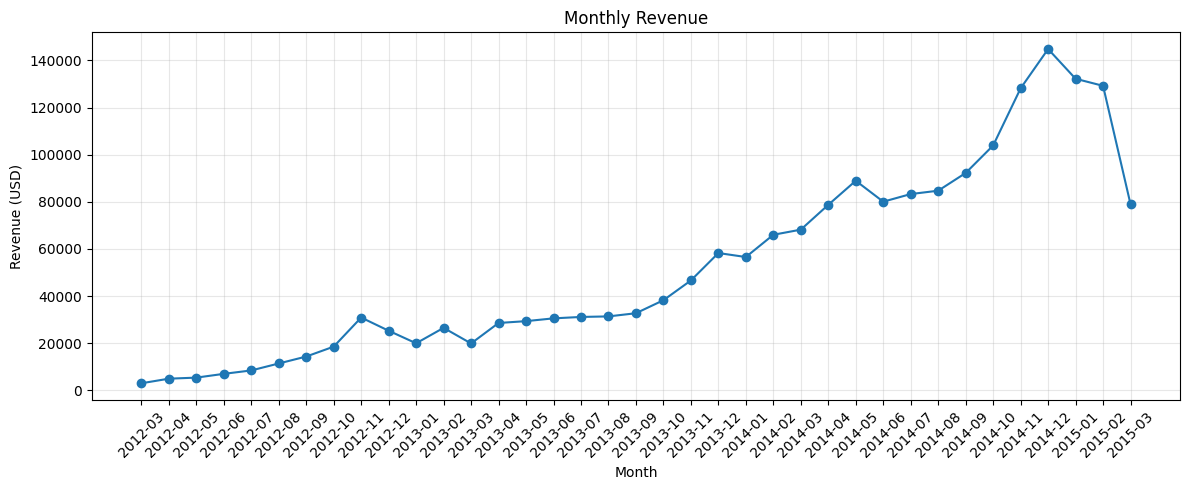

In [0]:
# Aggregate order revenue and distinct order count by month.
monthly_revenue_spark = (orders.filter(F.col("order_month").isNotNull()).groupBy("order_month")
    .agg(F.sum("price_usd").alias("revenue_usd"), F.countDistinct("order_id").alias("total_orders"))
    .orderBy("order_month"))
display(monthly_revenue_spark)

# Convert only the small monthly summary to Pandas for Matplotlib.
monthly_revenue_pd = monthly_revenue_spark.toPandas()
plt.figure(figsize=(12, 5))
plt.plot(monthly_revenue_pd["order_month"], monthly_revenue_pd["revenue_usd"], marker="o")
plt.title("Monthly Revenue"); plt.xlabel("Month"); plt.ylabel("Revenue (USD)")
plt.xticks(rotation=45); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### 2.2 Products generating the highest sales


product_id,product_name,units_sold,product_revenue_usd,distinct_orders
1,The Original Mr. Fuzzy,24226,1211057.7399998049,24226
2,The Forever Love Bear,5796,347702.0399999714,5796
3,The Birthday Sugar Panda,4985,229260.14999998664,4985
4,The Hudson River Mini bear,5018,150489.82000000397,5018


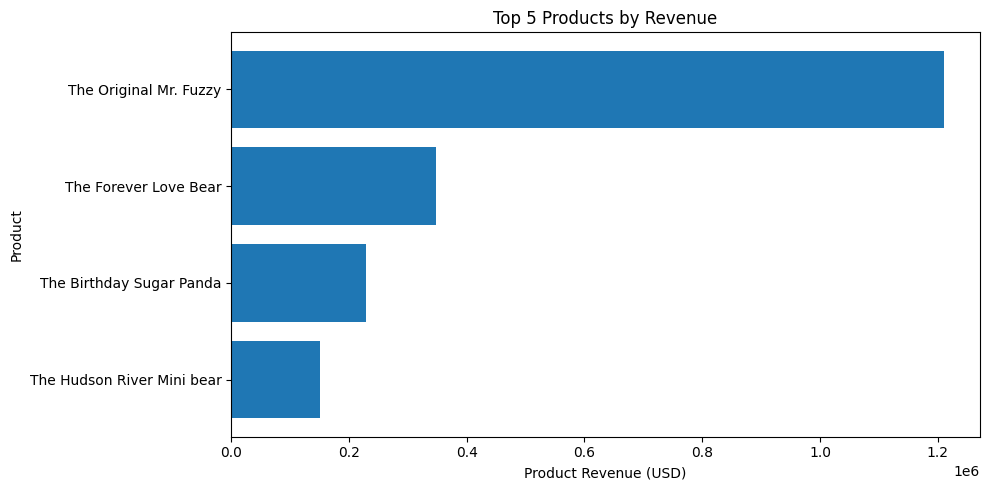

In [0]:
# Aggregate item counts, product revenue and distinct orders by product.
product_performance_spark = (order_items.groupBy("product_id")
    .agg(F.countDistinct("order_item_id").alias("units_sold"), F.sum("price_usd").alias("product_revenue_usd"), F.countDistinct("order_id").alias("distinct_orders"))
    .join(products.select("product_id", "product_name"), "product_id", "left")
    .select("product_id", "product_name", "units_sold", "product_revenue_usd", "distinct_orders")
    .orderBy(F.desc("product_revenue_usd")))
display(product_performance_spark)
product_pd = product_performance_spark.toPandas()
top5 = product_pd.head(5).sort_values("product_revenue_usd")
plt.figure(figsize=(10, 5)); plt.barh(top5["product_name"], top5["product_revenue_usd"])
plt.title("Top 5 Products by Revenue"); plt.xlabel("Product Revenue (USD)"); plt.ylabel("Product"); plt.tight_layout(); plt.show()

### 2.3 Customer purchasing behaviour


user_id,number_of_orders,customer_revenue_usd
276897,3,149.97
275098,3,235.95
122640,3,149.97
336150,3,209.95
158032,3,149.97
273501,3,169.97
83383,3,159.97
107850,3,149.97
318660,3,149.97
142410,3,219.96


summary,price_usd,cogs_usd,items_purchased
count,32313,32313,32313
mean,59.99163649304212,22.355406492734843,1.2386655525639836
stddev,17.808771047298574,6.238620558926895,0.42627447731999923
min,29.99,9.49,1
max,109.98,41.98,2


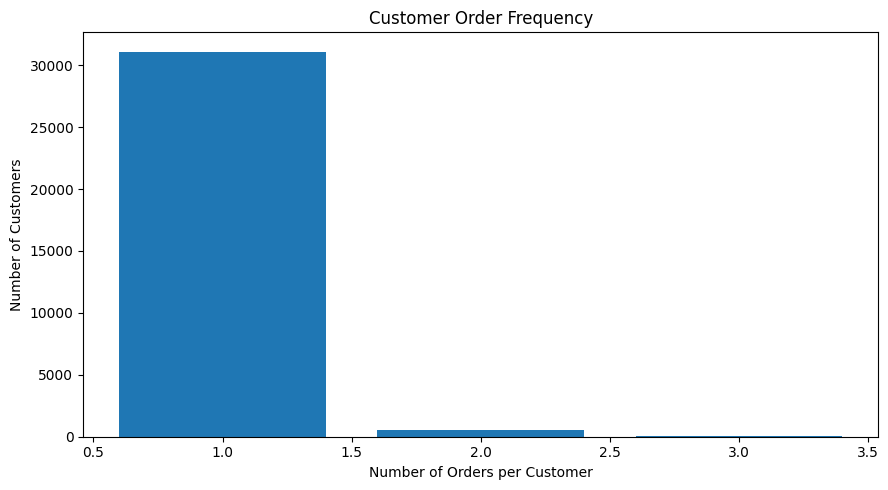

In [0]:
# Calculate customer order frequency and cumulative customer revenue.
orders_per_customer = orders.groupBy("user_id").agg(F.countDistinct("order_id").alias("number_of_orders"), F.sum("price_usd").alias("customer_revenue_usd"))
display(orders_per_customer.orderBy(F.desc("number_of_orders")).limit(20))

# Summarise order value, cost and basket size.
display(orders.select("price_usd", "cogs_usd", "items_purchased").describe())

# Count customers by their number of orders and chart the distribution.
frequency_spark = orders_per_customer.groupBy("number_of_orders").agg(F.count("*").alias("customers")).orderBy("number_of_orders")
frequency_pd = frequency_spark.toPandas()
plt.figure(figsize=(9, 5)); plt.bar(frequency_pd["number_of_orders"], frequency_pd["customers"])
plt.title("Customer Order Frequency"); plt.xlabel("Number of Orders per Customer"); plt.ylabel("Number of Customers"); plt.tight_layout(); plt.show()

### 2.4 Marketing channels attracting the most sessions


utm_source,session_count
gsearch,316035
NULL,83328
bsearch,62823
socialbook,10685


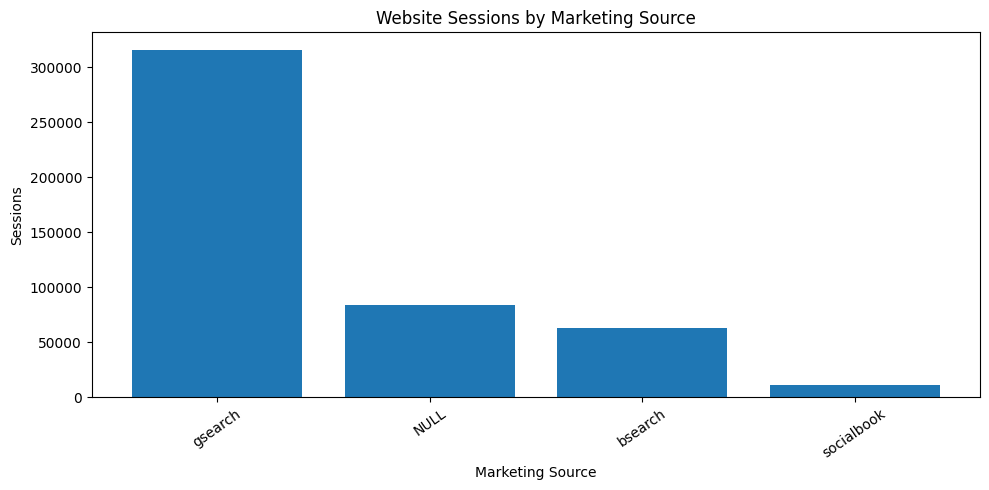

In [0]:
# Count distinct website sessions for each marketing source.
sessions_by_source = sessions.groupBy("utm_source").agg(F.countDistinct("website_session_id").alias("session_count")).orderBy(F.desc("session_count"))
display(sessions_by_source)
source_pd = sessions_by_source.toPandas()
plt.figure(figsize=(10, 5)); plt.bar(source_pd["utm_source"], source_pd["session_count"])
plt.title("Website Sessions by Marketing Source"); plt.xlabel("Marketing Source"); plt.ylabel("Sessions"); plt.xticks(rotation=35); plt.tight_layout(); plt.show()

### 2.5 Mobile versus desktop traffic


device_type,session_count
desktop,327027
mobile,145844


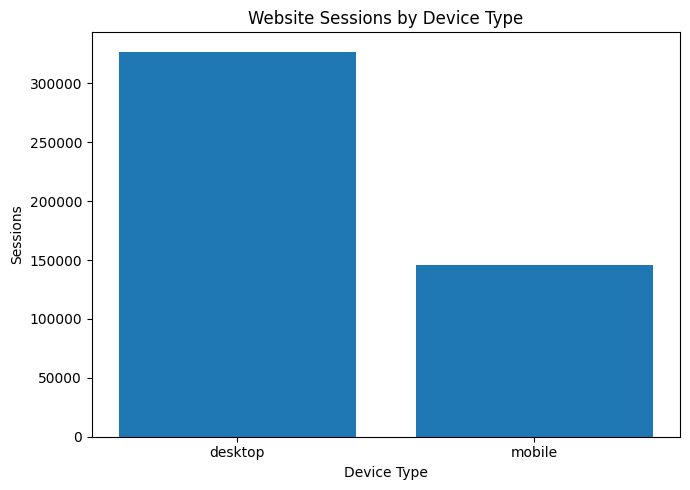

In [0]:
# Count distinct sessions for each device category.
sessions_by_device = sessions.groupBy("device_type").agg(F.countDistinct("website_session_id").alias("session_count")).orderBy(F.desc("session_count"))
display(sessions_by_device)
device_pd = sessions_by_device.toPandas()
plt.figure(figsize=(7, 5)); plt.bar(device_pd["device_type"], device_pd["session_count"])
plt.title("Website Sessions by Device Type"); plt.xlabel("Device Type"); plt.ylabel("Sessions"); plt.tight_layout(); plt.show()

### 2.6 Session-to-order conversion rate


In [0]:
# Calculate unique sessions and unique converting sessions.
total_sessions = sessions.select("website_session_id").distinct().count()
converting_sessions = orders.select("website_session_id").distinct().count()
conversion_rate_pct = (converting_sessions / total_sessions * 100) if total_sessions else 0
print(f"Total website sessions: {total_sessions:,}")
print(f"Sessions with an order: {converting_sessions:,}")
print(f"Session-to-order conversion rate: {conversion_rate_pct:.2f}%")

Total website sessions: 472,871
Sessions with an order: 32,313
Session-to-order conversion rate: 6.83%


### 2.7 Products with the highest refund activity


product_id,product_name,refund_count,refund_value_usd
1,The Original Mr. Fuzzy,1237,61837.62999999928
3,The Birthday Sugar Panda,301,13842.989999999945
2,The Forever Love Bear,129,7738.70999999998
4,The Hudson River Mini bear,64,1919.3600000000004


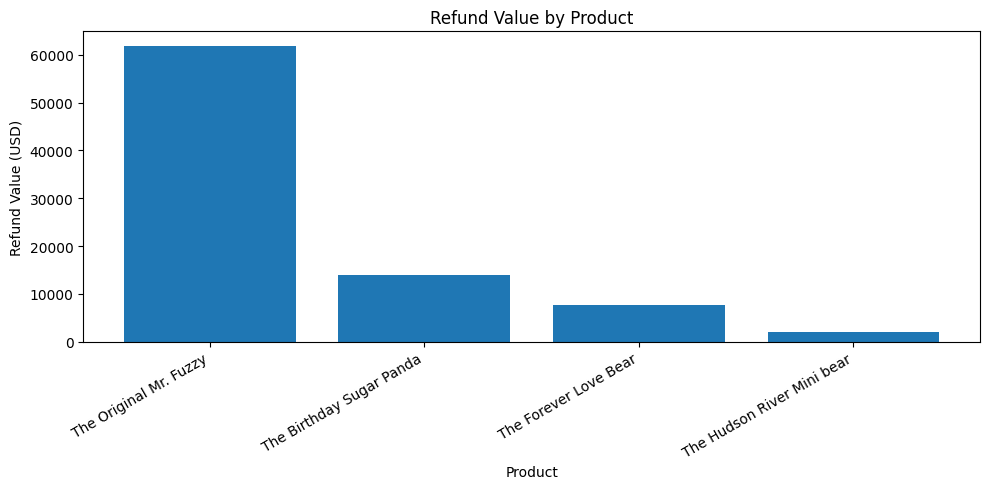

In [0]:
# Join refund records to the order item and product tables.
refund_details = (refunds.join(order_items.select("order_item_id", "product_id"), "order_item_id", "left")
    .join(products.select("product_id", "product_name"), "product_id", "left"))
refund_by_product = (refund_details.groupBy("product_id", "product_name")
    .agg(F.countDistinct("order_item_refund_id").alias("refund_count"), F.sum("refund_amount_usd").alias("refund_value_usd"))
    .orderBy(F.desc("refund_value_usd")))
display(refund_by_product)
refund_pd = refund_by_product.toPandas()
plt.figure(figsize=(10, 5)); plt.bar(refund_pd["product_name"].fillna("Unknown"), refund_pd["refund_value_usd"])
plt.title("Refund Value by Product"); plt.xlabel("Product"); plt.ylabel("Refund Value (USD)"); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

### 2.8 New versus returning sessions


session_type,sessions,converted_sessions,conversion_rate_pct
New,394318,26164,6.635253779944106
Returning,78553,6149,7.827835983348821


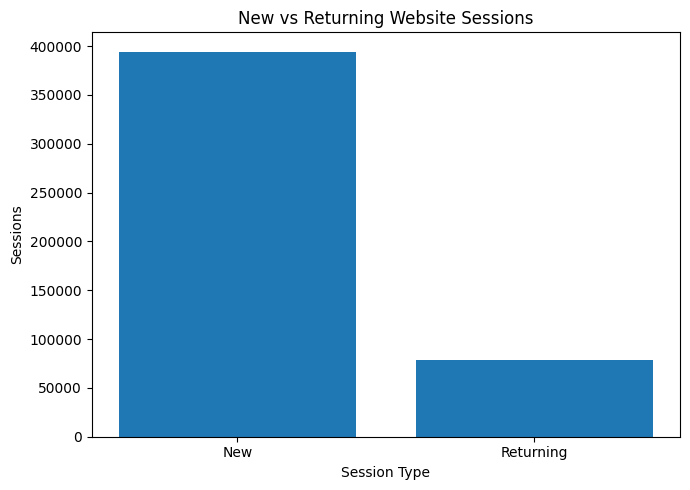

In [0]:
# Label each session as New or Returning.
sessions_typed = sessions.withColumn("session_type", F.when(F.col("is_repeat_session").cast("int") == 1, "Returning").otherwise("New"))

# Build a one-row-per-session conversion indicator from the orders table.
converted_ids = orders.select("website_session_id").distinct().withColumn("converted", F.lit(1))
session_outcomes = sessions_typed.join(converted_ids, "website_session_id", "left").fillna({"converted": 0})

# Compare session counts and converting sessions by session type.
conversion_by_type = (session_outcomes.groupBy("session_type")
    .agg(F.countDistinct("website_session_id").alias("sessions"),
         F.countDistinct(F.when(F.col("converted") == 1, F.col("website_session_id"))).alias("converted_sessions"))
    .withColumn("conversion_rate_pct", F.col("converted_sessions") / F.col("sessions") * 100))
display(conversion_by_type)

# Plot the number of new and returning sessions.
session_type_pd = sessions_typed.groupBy("session_type").agg(F.countDistinct("website_session_id").alias("session_count")).toPandas()
plt.figure(figsize=(7, 5)); plt.bar(session_type_pd["session_type"], session_type_pd["session_count"])
plt.title("New vs Returning Website Sessions"); plt.xlabel("Session Type"); plt.ylabel("Sessions"); plt.tight_layout(); plt.show()

## Task 3 – Statistical analysis and visualisation
### 3.1 Descriptive statistics


In [0]:
# Summarise order-level, item-level and refund measures.
display(orders.select("price_usd", "cogs_usd", "items_purchased").describe())
display(order_items.select("price_usd", "cogs_usd").describe())
display(refunds.select("refund_amount_usd").describe())

# Calculate pageviews per session and describe the distribution.
pageviews_per_session = pageviews.groupBy("website_session_id").agg(F.count("website_pageview_id").alias("pageview_count"))
display(pageviews_per_session.select("pageview_count").describe())

summary,price_usd,cogs_usd,items_purchased
count,32313,32313,32313
mean,59.99163649304212,22.355406492734843,1.2386655525639836
stddev,17.808771047298574,6.238620558926895,0.42627447731999923
min,29.99,9.49,1
max,109.98,41.98,2


summary,price_usd,cogs_usd
count,40025,40025
mean,48.43247345408267,18.047976264827284
stddev,8.012370188188969,3.8568209527043864
min,29.99,9.49
max,59.99,22.49


summary,refund_amount_usd
count,1731
mean,49.300225303293615
stddev,4.956015146685884
min,29.99
max,59.99


summary,pageview_count
count,421956
mean,2.4850339845860705
stddev,1.8042478698285815
min,1
max,7


### 3.2 Relationship between website traffic and orders


session_date,sessions,orders
2012-03-19,137,2
2012-03-20,161,6
2012-03-21,191,9
2012-03-22,177,4
2012-03-23,156,3
2012-03-24,74,1
2012-03-25,73,4
2012-03-26,175,9
2012-03-27,163,2
2012-03-28,165,5


Daily sessions/orders correlation: 0.956


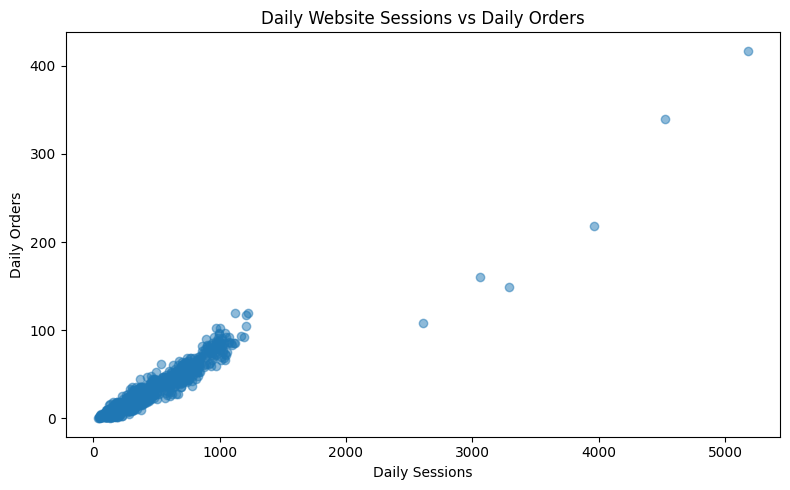

In [0]:
# Count daily sessions and daily orders independently.
daily_sessions = sessions.filter(F.col("session_date").isNotNull()).groupBy("session_date").agg(F.countDistinct("website_session_id").alias("sessions"))
daily_orders = orders.filter(F.col("order_date").isNotNull()).groupBy(F.col("order_date").alias("session_date")).agg(F.countDistinct("order_id").alias("orders"))
daily_traffic_orders = daily_sessions.join(daily_orders, "session_date", "left").fillna({"orders": 0}).orderBy("session_date")
display(daily_traffic_orders)

# Calculate Pearson's correlation coefficient on daily aggregate values.
traffic_order_corr = daily_traffic_orders.stat.corr("sessions", "orders")
print(f"Daily sessions/orders correlation: {traffic_order_corr:.3f}")

# Plot the daily relationship using the small aggregated table.
daily_pd = daily_traffic_orders.toPandas()
plt.figure(figsize=(8, 5)); plt.scatter(daily_pd["sessions"], daily_pd["orders"], alpha=0.5)
plt.title("Daily Website Sessions vs Daily Orders"); plt.xlabel("Daily Sessions"); plt.ylabel("Daily Orders"); plt.tight_layout(); plt.show()

### 3.3 Compare sales performance across months


order_month,total_orders,total_revenue_usd,average_order_value_usd
2012-03,60,2999.399999999996,49.98999999999993
2012-04,99,4949.0099999999875,49.989999999999874
2012-05,108,5398.9199999999855,49.98999999999987
2012-06,140,6998.5999999999785,49.989999999999846
2012-07,169,8448.309999999972,49.98999999999984
2012-08,228,11397.71999999996,49.989999999999824
2012-09,287,14347.129999999946,49.98999999999981
2012-10,371,18546.290000000008,49.99000000000002
2012-11,618,30893.820000000404,49.990000000000656
2012-12,506,25294.940000000224,49.99000000000044


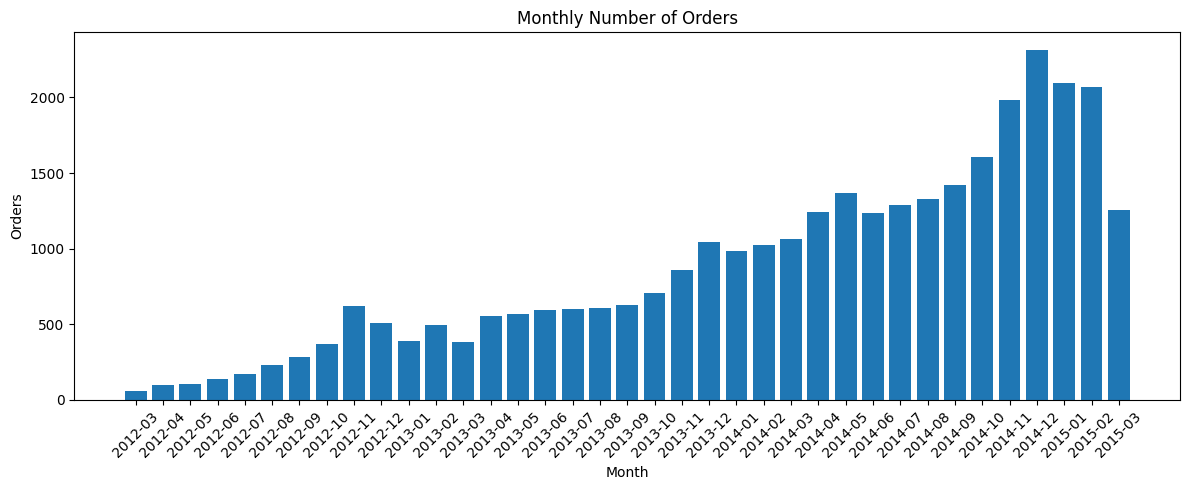

In [0]:
# Aggregate monthly order metrics.
monthly_performance = (orders.filter(F.col("order_month").isNotNull()).groupBy("order_month")
    .agg(F.countDistinct("order_id").alias("total_orders"), F.sum("price_usd").alias("total_revenue_usd"), F.avg("price_usd").alias("average_order_value_usd"))
    .orderBy("order_month"))
display(monthly_performance)
monthly_pd = monthly_performance.toPandas()
plt.figure(figsize=(12, 5)); plt.bar(monthly_pd["order_month"], monthly_pd["total_orders"])
plt.title("Monthly Number of Orders"); plt.xlabel("Month"); plt.ylabel("Orders"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

### 3.4 Relationship between product sales and refunds

product_id,product_name,units_sold,product_revenue_usd,distinct_orders,refund_count,refund_value_usd,refund_value_pct_of_sales
3,The Birthday Sugar Panda,4985,229260.14999998664,4985,301,13842.989999999945,6.038114343029415
4,The Hudson River Mini bear,5018,150489.82000000397,5018,64,1919.3600000000004,1.2754085292945063
2,The Forever Love Bear,5796,347702.0399999714,5796,129,7738.70999999998,2.225672877846968
1,The Original Mr. Fuzzy,24226,1211057.7399998049,24226,1237,61837.62999999928,5.106084372162903


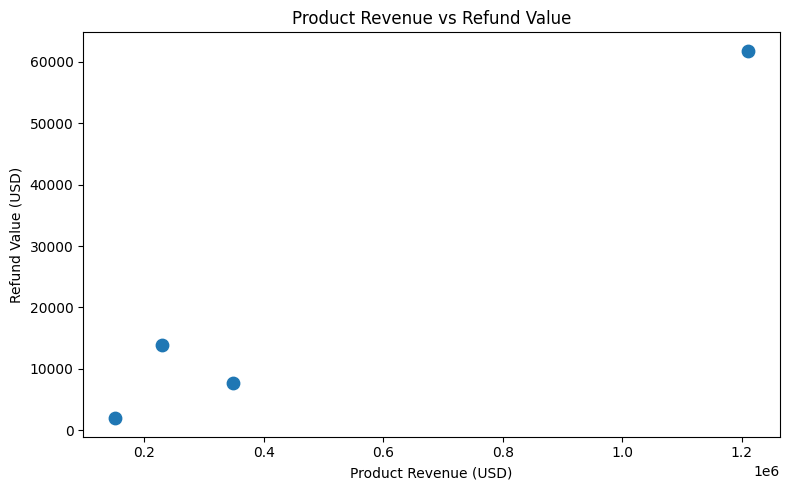

In [0]:
# Combine product revenue and refund summaries.
sales_refunds = (product_performance_spark.join(refund_by_product.select("product_id", "refund_count", "refund_value_usd"), "product_id", "left")
    .fillna({"refund_count": 0, "refund_value_usd": 0.0})
    .withColumn("refund_value_pct_of_sales", F.when(F.col("product_revenue_usd") > 0, F.col("refund_value_usd") / F.col("product_revenue_usd") * 100).otherwise(0)))
display(sales_refunds)
sales_refunds_pd = sales_refunds.toPandas()
plt.figure(figsize=(8, 5)); plt.scatter(sales_refunds_pd["product_revenue_usd"], sales_refunds_pd["refund_value_usd"], s=80)
plt.title("Product Revenue vs Refund Value"); plt.xlabel("Product Revenue (USD)"); plt.ylabel("Refund Value (USD)"); plt.tight_layout(); plt.show()

### 3.5 Additional visualisation – most viewed pages


pageview_url,pageviews
/products,230534
/the-original-mr-fuzzy,145884
/lander-2,131170
/home,119993
/cart,82603
/lander-3,69969
/shipping,56124
/lander-1,47574
/lander-5,43865
/billing-2,41696


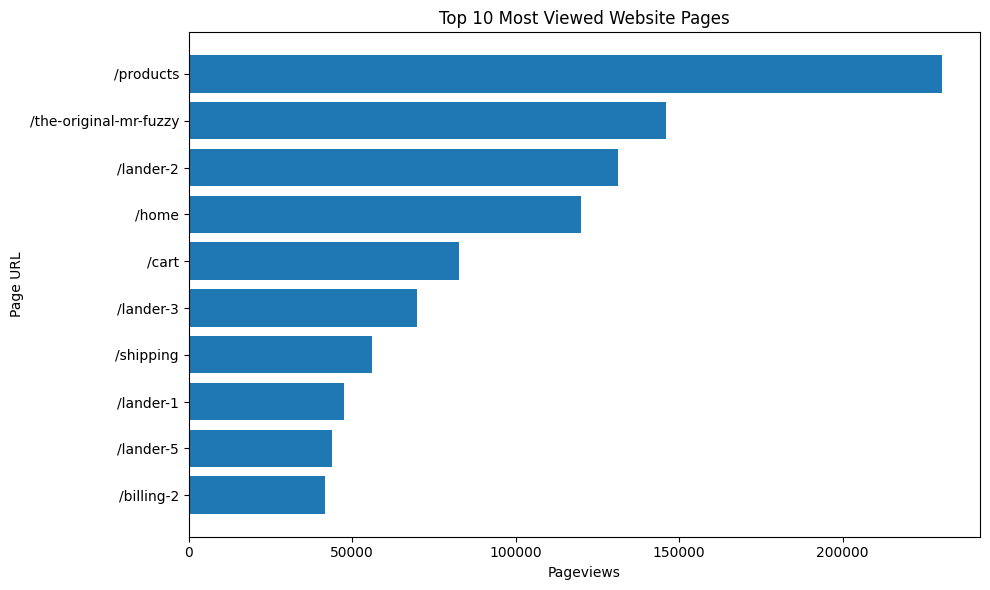

In [0]:
# Count views per URL and keep only the top ten results.
top_pages = pageviews.groupBy("pageview_url").agg(F.count("website_pageview_id").alias("pageviews")).orderBy(F.desc("pageviews")).limit(10)
display(top_pages)
top_pages_pd = top_pages.toPandas().sort_values("pageviews")
plt.figure(figsize=(10, 6)); plt.barh(top_pages_pd["pageview_url"], top_pages_pd["pageviews"])
plt.title("Top 10 Most Viewed Website Pages"); plt.xlabel("Pageviews"); plt.ylabel("Page URL"); plt.tight_layout(); plt.show()

### 3.6 Additional visualisation – daily revenue trend


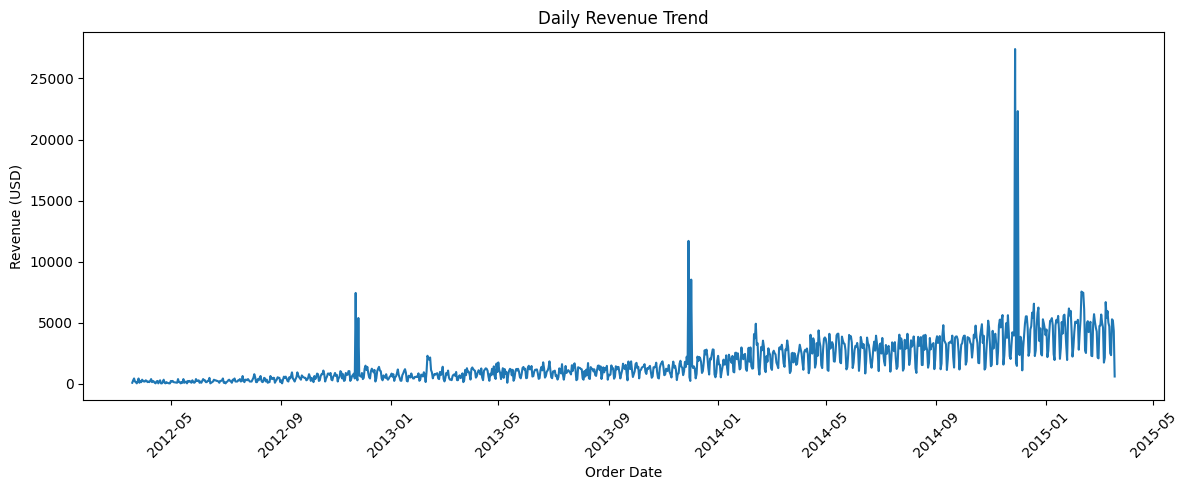

Error in callback <bound method UserNamespaceCommandHook.post_run_cell of <dbruntime.DatasetInfo.UserNamespaceCommandHook object at 0xffa61b445d00>> (for post_run_cell), with arguments args (<ExecutionResult object at ffa5c309be60, execution_count=85 error_before_exec=None error_in_exec=None info=<ExecutionInfo object at ffa5c3098530, raw_cell="# Sum order-level revenue by date.
daily_revenue =.." transformed_cell="# Sum order-level revenue by date.
daily_revenue =.." store_history=True silent=False shell_futures=True cell_id=4624469815067863> result=None>,),kwargs {}:


In [0]:
# Sum order-level revenue by date.
daily_revenue = orders.filter(F.col("order_date").isNotNull()).groupBy("order_date").agg(F.sum("price_usd").alias("revenue_usd")).orderBy("order_date")
daily_revenue_pd = daily_revenue.toPandas()
plt.figure(figsize=(12, 5)); plt.plot(daily_revenue_pd["order_date"], daily_revenue_pd["revenue_usd"])
plt.title("Daily Revenue Trend"); plt.xlabel("Order Date"); plt.ylabel("Revenue (USD)"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## Task 4 – Interpretation and recommendations
### 4.1 Headline business metrics


In [0]:
# Calculate key business metrics.
order_metrics = orders.agg(F.countDistinct("order_id").alias("unique_orders"), F.sum("price_usd").alias("total_revenue_usd"), F.avg("price_usd").alias("average_order_value_usd")).first().asDict()
refund_metrics = refunds.agg(F.countDistinct("order_item_refund_id").alias("total_refunds"), F.sum("refund_amount_usd").alias("total_refund_value_usd")).first().asDict()
print("ORDER METRICS")
for k, v in order_metrics.items(): print(f"{k}: {v:,.2f}" if v is not None else f"{k}: None")
print("REFUND METRICS")
for k, v in refund_metrics.items(): print(f"{k}: {v:,.2f}" if v is not None else f"{k}: None")
print(f"Unique sessions: {total_sessions:,}")
print(f"Converting sessions: {converting_sessions:,}")
print(f"Session conversion rate: {conversion_rate_pct:.2f}%")

ORDER METRICS
unique_orders: 32,313.00
total_revenue_usd: 1,938,509.75
average_order_value_usd: 59.99
REFUND METRICS
total_refunds: 1,731.00
total_refund_value_usd: 85,338.69
Unique sessions: 472,871
Converting sessions: 32,313
Session conversion rate: 6.83%


### 4.2 Highest and lowest revenue months; leading product, source and device

In [0]:
# Identify strongest and weakest months in the observed data.
high_month = monthly_performance.orderBy(F.desc("total_revenue_usd")).first()
low_month = monthly_performance.orderBy(F.asc("total_revenue_usd")).first()
print("Highest revenue month:", high_month["order_month"], f"${high_month['total_revenue_usd']:,.2f}")
print("Lowest revenue month:", low_month["order_month"], f"${low_month['total_revenue_usd']:,.2f}")

# Identify leading product, marketing source and device based on the relevant measure.
top_product = product_performance_spark.first()
top_source = sessions_by_source.first()
top_device = sessions_by_device.first()
print("Top product:", top_product["product_name"], f"${top_product['product_revenue_usd']:,.2f}")
print("Top marketing source:", top_source["utm_source"], f"({top_source['session_count']:,} sessions)")
print("Top device:", top_device["device_type"], f"({top_device['session_count']:,} sessions)")

Highest revenue month: 2014-12 $144,823.02
Lowest revenue month: 2012-03 $2,999.40
Top product: The Original Mr. Fuzzy $1,211,057.74
Top marketing source: gsearch (316,035 sessions)
Top device: desktop (327,027 sessions)
